In [1]:
import pandas as pd

print("ChurnScope is starting!")
print("Pandas version:", pd.__version__)

ChurnScope is starting!
Pandas version: 3.0.6


In [2]:
from pathlib import Path
import pandas as pd

DATA_PATH = (
    Path.cwd().parent
    / "data"
    / "raw"
    / "Telco-Customer-Churn.csv"
)

df = pd.read_csv(DATA_PATH)

print("CHURNSCOPE — CUSTOMER DATA")
print("=" * 35)

print(f"Total customers: {df.shape[0]:,}")
print(f"Total columns: {df.shape[1]}")

display(df.head())

CHURNSCOPE — CUSTOMER DATA
Total customers: 7,043
Total columns: 21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
print("1. DATASET INFORMATION")
print("=" * 40)
df.info()

print("\n2. MISSING VALUES")
print("=" * 40)
print(df.isnull().sum().sort_values(ascending=False))

print("\n3. DUPLICATE ROWS")
print("=" * 40)
print(df.duplicated().sum())

print("\n4. CHURN DISTRIBUTION")
print("=" * 40)
print(df["Churn"].value_counts())

print("\n5. CHURN PERCENTAGE")
print("=" * 40)
print((df["Churn"].value_counts(normalize=True) * 100).round(2))

1. DATASET INFORMATION
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-nul

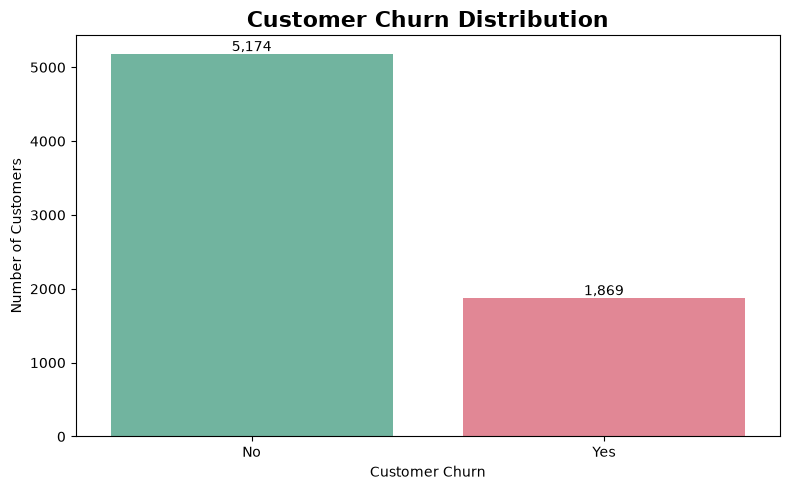

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

churn_counts = df["Churn"].value_counts().reindex(["No", "Yes"])

plt.figure(figsize=(8, 5))
ax = sns.barplot(
    x=churn_counts.index,
    y=churn_counts.values,
    hue=churn_counts.index,
    palette={"No": "#66BFA3", "Yes": "#F0788B"},
    legend=False
)

plt.title("Customer Churn Distribution", fontsize=16, fontweight="bold")
plt.xlabel("Customer Churn")
plt.ylabel("Number of Customers")

for bar in ax.patches:
    ax.annotate(
        f"{bar.get_height():,.0f}",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

CHURN RATE BY CONTRACT TYPE
Contract
Month-to-month    42.71
One year          11.27
Two year           2.83
Name: Churn, dtype: float64


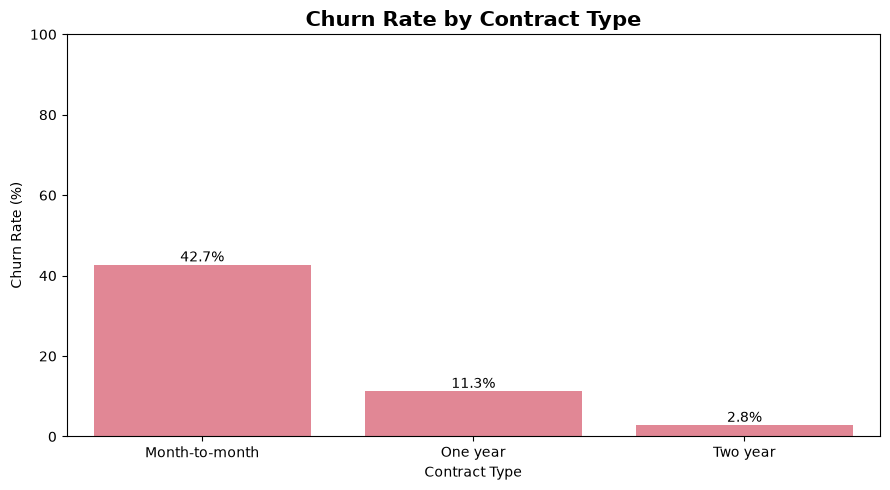

In [5]:
# Churn rate by contract type
contract_churn = (
    df.groupby("Contract")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .sort_values(ascending=False)
)

print("CHURN RATE BY CONTRACT TYPE")
print(contract_churn.round(2))

plt.figure(figsize=(9, 5))
ax = sns.barplot(
    x=contract_churn.index,
    y=contract_churn.values,
    color="#F0788B"
)

plt.title("Churn Rate by Contract Type", fontsize=15, fontweight="bold")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 100)

for bar in ax.patches:
    ax.annotate(
        f"{bar.get_height():.1f}%",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

CUSTOMER TENURE BY CHURN STATUS


,count,mean,std,min,25%,50%,75%,max
Churn,,,,,,,,
No,5174.0,37.57,24.11,0.0,15.0,38.0,61.0,72.0
Yes,1869.0,17.98,19.53,1.0,2.0,10.0,29.0,72.0


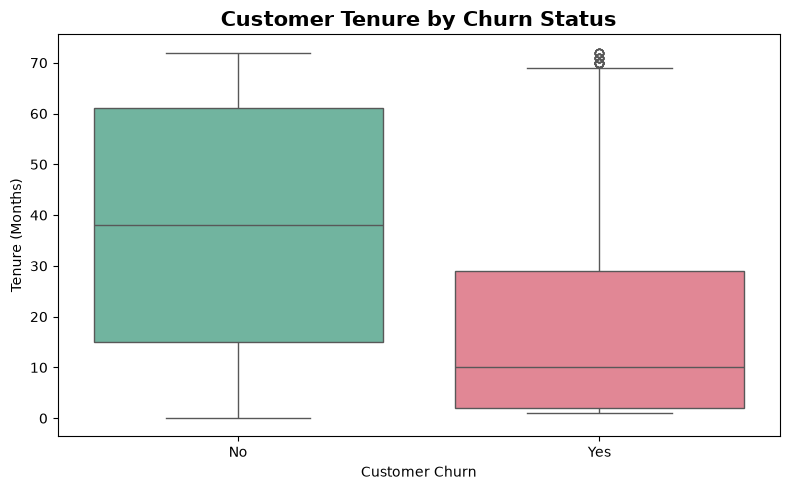

In [6]:
tenure_churn = (
    df.groupby("Churn")["tenure"]
    .describe()
    .round(2)
)

print("CUSTOMER TENURE BY CHURN STATUS")
display(tenure_churn)

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="tenure",
    hue="Churn",
    palette={"No": "#66BFA3", "Yes": "#F0788B"},
    legend=False
)

plt.title("Customer Tenure by Churn Status", fontsize=15, fontweight="bold")
plt.xlabel("Customer Churn")
plt.ylabel("Tenure (Months)")
plt.tight_layout()
plt.show()

MONTHLY CHARGES BY CHURN STATUS


,mean,median
Churn,,
No,61.27,64.43
Yes,74.44,79.65


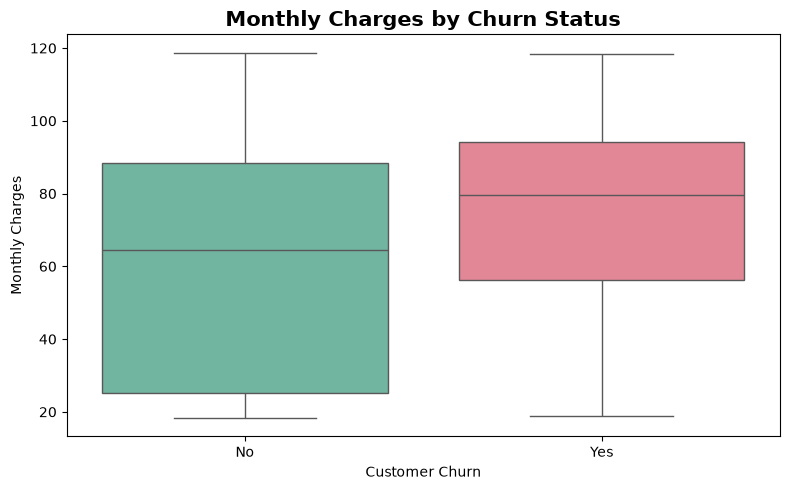

In [7]:
print("MONTHLY CHARGES BY CHURN STATUS")

display(
    df.groupby("Churn")["MonthlyCharges"]
    .agg(["mean", "median"])
    .round(2)
)

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges",
    hue="Churn",
    palette={"No": "#66BFA3", "Yes": "#F0788B"},
    legend=False
)

plt.title("Monthly Charges by Churn Status", fontsize=15, fontweight="bold")
plt.xlabel("Customer Churn")
plt.ylabel("Monthly Charges")
plt.tight_layout()
plt.show()

In [8]:
charges = df.groupby("Churn")["MonthlyCharges"].agg(
    ["mean", "median"]
).round(2)

print(charges)

        mean  median
Churn               
No     61.27   64.43
Yes    74.44   79.65


CHURN RATE BY INTERNET SERVICE
InternetService
Fiber optic    41.89
DSL            18.96
No              7.40
Name: Churn, dtype: float64


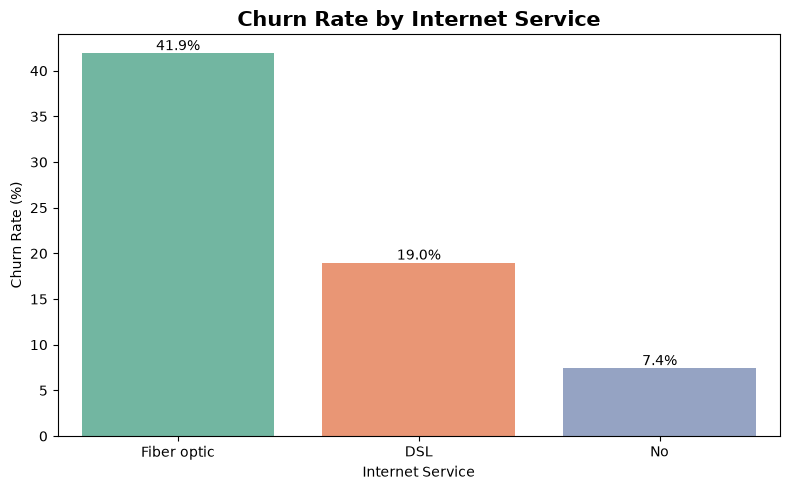

In [9]:
internet_churn = (
    df.groupby("InternetService")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .sort_values(ascending=False)
)

print("CHURN RATE BY INTERNET SERVICE")
print(internet_churn.round(2))

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    x=internet_churn.index,
    y=internet_churn.values,
    hue=internet_churn.index,
    palette="Set2",
    legend=False
)

plt.title("Churn Rate by Internet Service", fontsize=15, fontweight="bold")
plt.xlabel("Internet Service")
plt.ylabel("Churn Rate (%)")

for bar in ax.patches:
    ax.annotate(
        f"{bar.get_height():.1f}%",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

CHURN RATE BY PAYMENT METHOD
PaymentMethod
Electronic check             45.29
Mailed check                 19.11
Bank transfer (automatic)    16.71
Credit card (automatic)      15.24
Name: Churn, dtype: float64


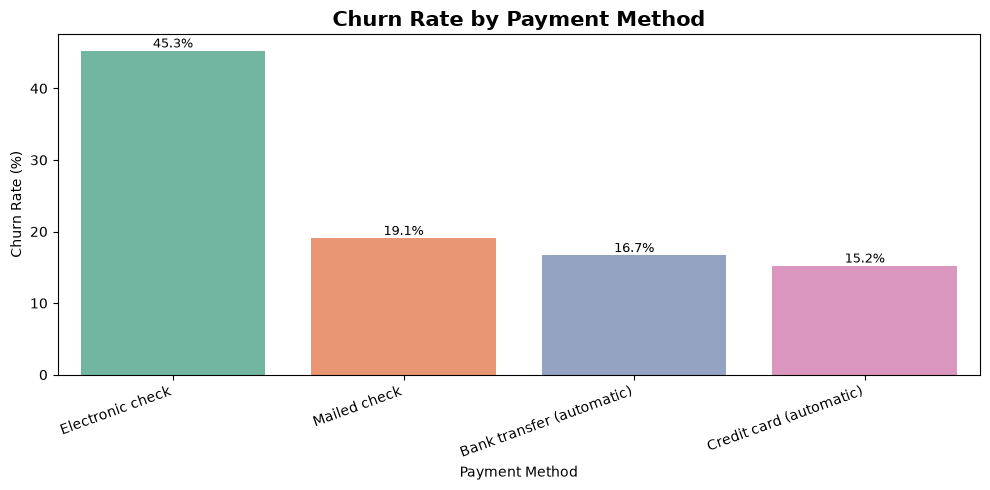

In [10]:
payment_churn = (
    df.groupby("PaymentMethod")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .sort_values(ascending=False)
)

print("CHURN RATE BY PAYMENT METHOD")
print(payment_churn.round(2))

plt.figure(figsize=(10, 5))

ax = sns.barplot(
    x=payment_churn.index,
    y=payment_churn.values,
    hue=payment_churn.index,
    palette="Set2",
    legend=False
)

plt.title("Churn Rate by Payment Method", fontsize=15, fontweight="bold")
plt.xlabel("Payment Method")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=20, ha="right")

for bar in ax.patches:
    ax.annotate(
        f"{bar.get_height():.1f}%",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.tight_layout()
plt.show()

In [11]:
print("DATA TYPES")
print(df.dtypes)

print("\nMISSING VALUES")
print(df.isna().sum().sort_values(ascending=False))

print("\nTOTAL CHARGES — CURRENT DATA TYPE")
print(df["TotalCharges"].dtype)

print("\nBLANK TOTAL CHARGES")
print((df["TotalCharges"].astype(str).str.strip() == "").sum())

DATA TYPES
customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object

MISSING VALUES
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling   

In [12]:
# Convert TotalCharges from text to numeric
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"].astype(str).str.strip(),
    errors="coerce"
)

print("TOTAL CHARGES DATA TYPE:")
print(df["TotalCharges"].dtype)

print("\nMISSING TOTAL CHARGES:")
print(df["TotalCharges"].isna().sum())

print("\nCUSTOMERS WITH MISSING TOTAL CHARGES:")
display(df[df["TotalCharges"].isna()][["customerID", "tenure", "TotalCharges", "Churn"]])

TOTAL CHARGES DATA TYPE:
float64

MISSING TOTAL CHARGES:
11

CUSTOMERS WITH MISSING TOTAL CHARGES:


,customerID,tenure,TotalCharges,Churn
488,4472-LVYGI,0,NaN,No
753,3115-CZMZD,0,NaN,No
936,5709-LVOEQ,0,NaN,No
1082,4367-NUYAO,0,NaN,No
1340,1371-DWPAZ,0,NaN,No
3331,7644-OMVMY,0,NaN,No
3826,3213-VVOLG,0,NaN,No
4380,2520-SGTTA,0,NaN,No
5218,2923-ARZLG,0,NaN,No
6670,4075-WKNIU,0,NaN,No


In [13]:
# Fill missing TotalCharges for zero-tenure customers
mask = (df["TotalCharges"].isna()) & (df["tenure"] == 0)

df.loc[mask, "TotalCharges"] = 0

print("Missing TotalCharges remaining:", df["TotalCharges"].isna().sum())
print("Total customers retained:", len(df))
print("TotalCharges data type:", df["TotalCharges"].dtype)

Missing TotalCharges remaining: 0
Total customers retained: 7043
TotalCharges data type: float64


In [14]:
print("FINAL DATA QUALITY CHECK")
print("=" * 35)

print("Duplicate rows:", df.duplicated().sum())
print("Missing values:", df.isna().sum().sum())
print("Unique customer IDs:", df["customerID"].nunique())
print("Total rows:", len(df))

print("\nSUMMARY STATISTICS")
display(df[["tenure", "MonthlyCharges", "TotalCharges"]].describe().round(2))

FINAL DATA QUALITY CHECK
Duplicate rows: 0
Missing values: 0
Unique customer IDs: 7043
Total rows: 7043

SUMMARY STATISTICS


,tenure,MonthlyCharges,TotalCharges
count,7043.00,7043.00,7043.00
mean,32.37,64.76,2279.73
std,24.56,30.09,2266.79
min,0.00,18.25,0.00
25%,9.00,35.50,398.55
50%,29.00,70.35,1394.55
75%,55.00,89.85,3786.60
max,72.00,118.75,8684.80


In [15]:
# Compare churn across key customer groups

def churn_summary(column):
    result = (
        df.groupby(column, dropna=False)
        .agg(
            Customers=("Churn", "size"),
            Churned=("Churn", lambda x: (x == "Yes").sum())
        )
    )

    result["ChurnRate_%"] = (
        result["Churned"] / result["Customers"] * 100
    ).round(2)

    return result.sort_values("ChurnRate_%", ascending=False)


for column in ["Contract", "InternetService", "PaymentMethod"]:
    print(f"\n{'=' * 45}")
    print(f"CHURN BY {column.upper()}")
    print("=" * 45)
    display(churn_summary(column))


CHURN BY CONTRACT


,Customers,Churned,ChurnRate_%
Contract,,,
Month-to-month,3875,1655,42.71
One year,1473,166,11.27
Two year,1695,48,2.83



CHURN BY INTERNETSERVICE


,Customers,Churned,ChurnRate_%
InternetService,,,
Fiber optic,3096,1297,41.89
DSL,2421,459,18.96
No,1526,113,7.40



CHURN BY PAYMENTMETHOD


,Customers,Churned,ChurnRate_%
PaymentMethod,,,
Electronic check,2365,1071,45.29
Mailed check,1612,308,19.11
Bank transfer (automatic),1544,258,16.71
Credit card (automatic),1522,232,15.24


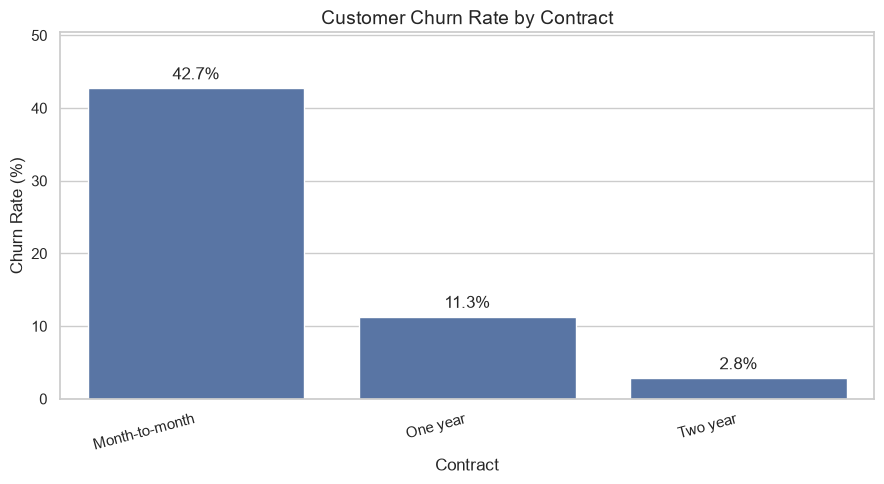

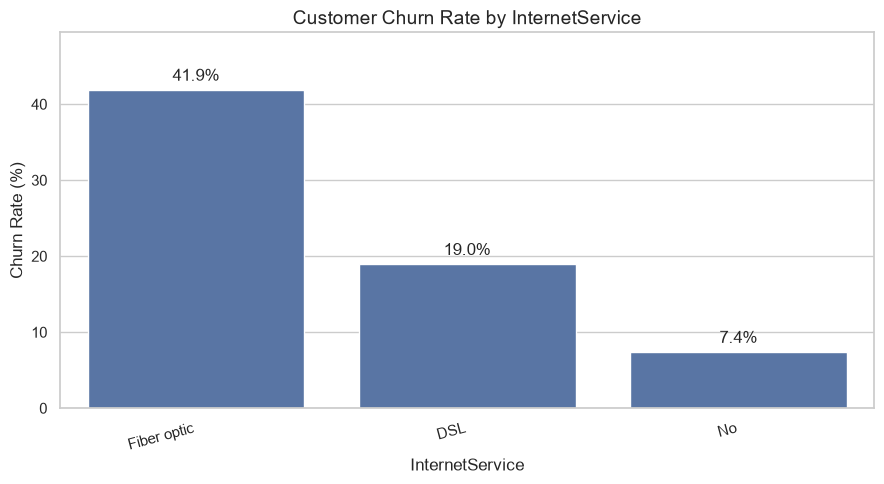

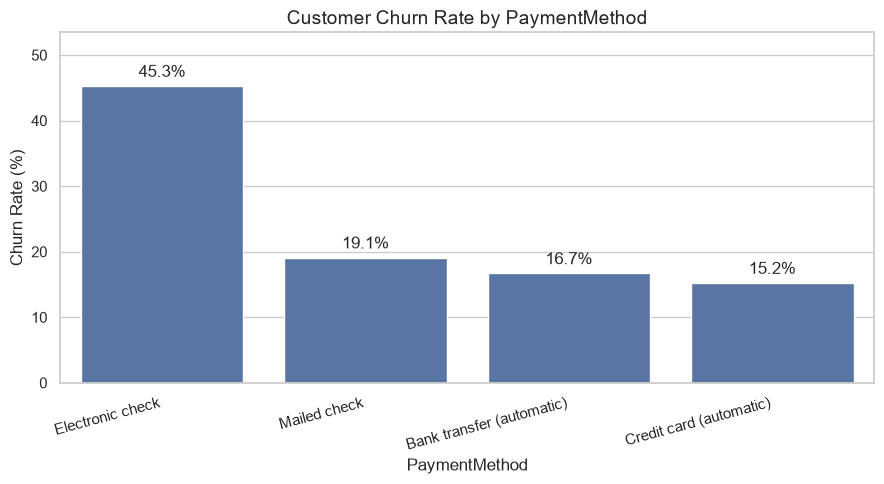

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

columns = [
    "Contract",
    "InternetService",
    "PaymentMethod"
]

for column in columns:
    summary = churn_summary(column).reset_index()

    plt.figure(figsize=(9, 5))

    ax = sns.barplot(
        data=summary,
        x=column,
        y="ChurnRate_%"
    )

    ax.bar_label(
        ax.containers[0],
        fmt="%.1f%%",
        padding=4
    )

    plt.title(
        f"Customer Churn Rate by {column}",
        fontsize=14
    )
    plt.xlabel(column)
    plt.ylabel("Churn Rate (%)")

    plt.ylim(
        0,
        summary["ChurnRate_%"].max() * 1.18
    )

    plt.xticks(rotation=15, ha="right")
    plt.tight_layout()
    plt.show()

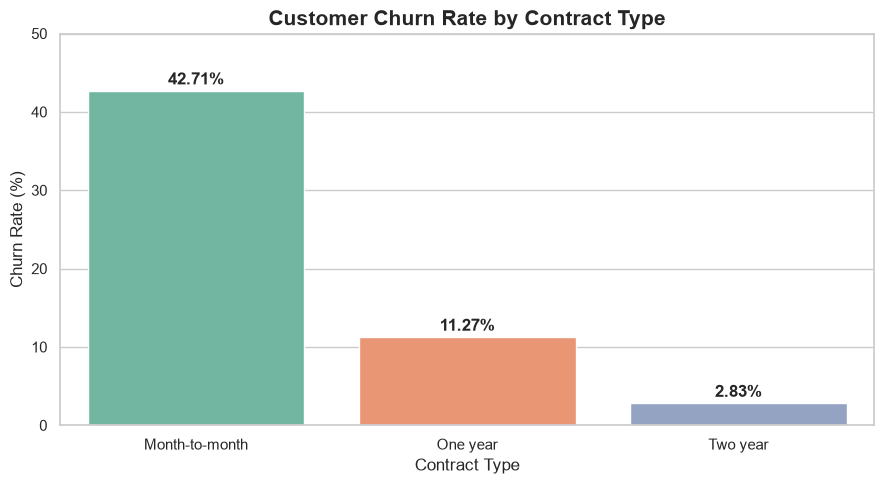

In [17]:

import matplotlib.pyplot as plt
import seaborn as sns

# Calculate churn rate by contract
contract_churn = churn_summary("Contract").reset_index()

# Create chart
plt.figure(figsize=(9, 5))

sns.barplot(
    data=contract_churn,
    x="Contract",
    y="ChurnRate_%",
    hue="Contract",
    palette="Set2",
    legend=False
)

plt.title("Customer Churn Rate by Contract Type", fontsize=15, fontweight="bold")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 50)

for i, value in enumerate(contract_churn["ChurnRate_%"]):
    plt.text(i, value + 0.8, f"{value:.2f}%", ha="center", fontweight="bold")

plt.tight_layout()
plt.show()


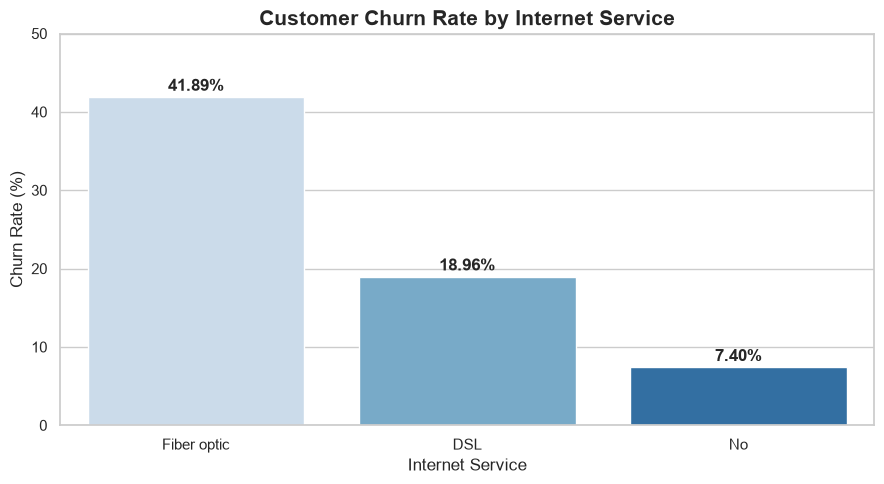

In [18]:

internet_churn = churn_summary("InternetService").reset_index()

plt.figure(figsize=(9, 5))

sns.barplot(
    data=internet_churn,
    x="InternetService",
    y="ChurnRate_%",
    hue="InternetService",
    palette="Blues",
    legend=False
)

plt.title("Customer Churn Rate by Internet Service", fontsize=15, fontweight="bold")
plt.xlabel("Internet Service")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 50)

for i, value in enumerate(internet_churn["ChurnRate_%"]):
    plt.text(i, value + 0.8, f"{value:.2f}%", ha="center", fontweight="bold")

plt.tight_layout()
plt.show()


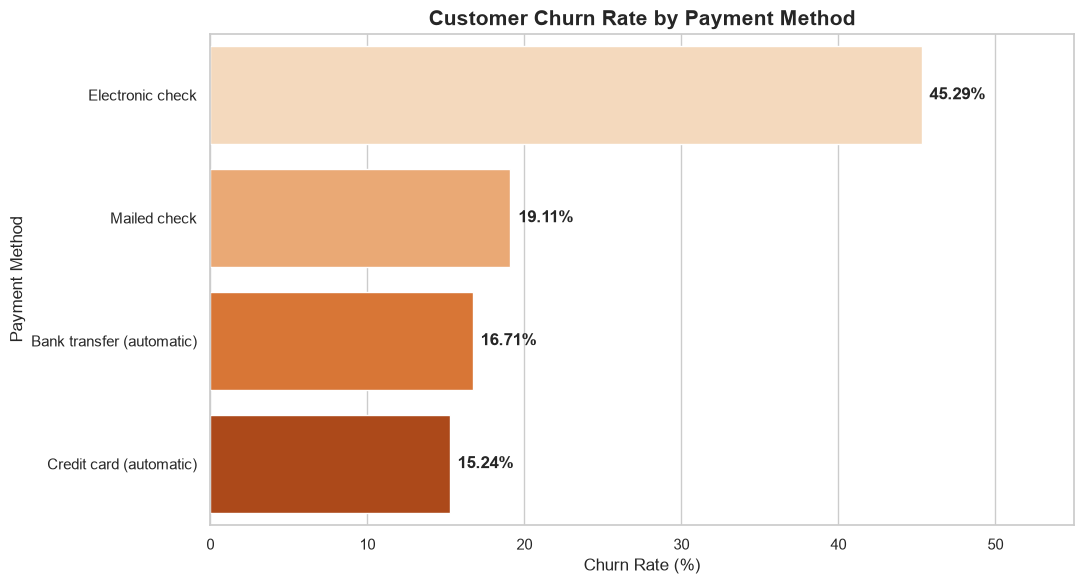

In [19]:

payment_churn = churn_summary("PaymentMethod").reset_index()

plt.figure(figsize=(11, 6))

sns.barplot(
    data=payment_churn,
    x="ChurnRate_%",
    y="PaymentMethod",
    hue="PaymentMethod",
    palette="Oranges",
    legend=False
)

plt.title("Customer Churn Rate by Payment Method", fontsize=15, fontweight="bold")
plt.xlabel("Churn Rate (%)")
plt.ylabel("Payment Method")
plt.xlim(0, 55)

for i, value in enumerate(payment_churn["ChurnRate_%"]):
    plt.text(value + 0.5, i, f"{value:.2f}%", va="center", fontweight="bold")

plt.tight_layout()
plt.show()


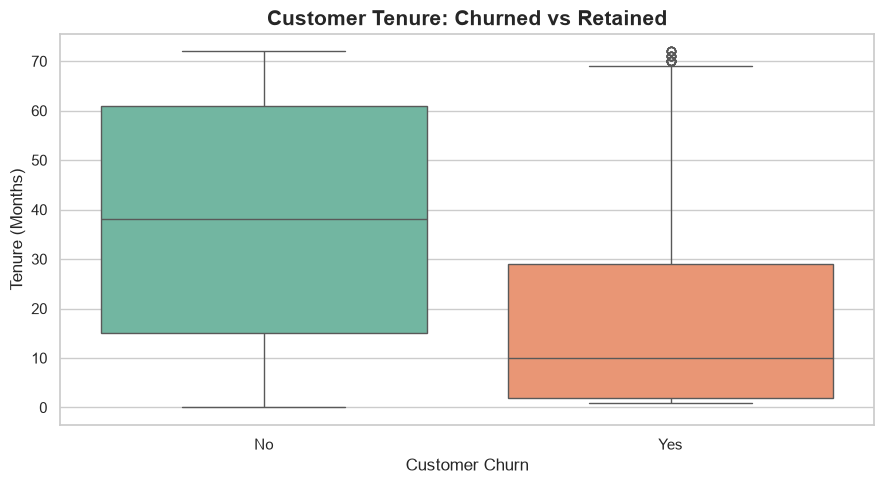

In [20]:

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="tenure",
    hue="Churn",
    palette="Set2",
    legend=False
)

plt.title("Customer Tenure: Churned vs Retained", fontsize=15, fontweight="bold")
plt.xlabel("Customer Churn")
plt.ylabel("Tenure (Months)")

plt.tight_layout()
plt.show()


In [21]:

total_customers = len(df)
churned_customers = (df["Churn"] == "Yes").sum()
retained_customers = (df["Churn"] == "No").sum()

overall_churn_rate = churned_customers / total_customers * 100
retention_rate = retained_customers / total_customers * 100

print("=" * 45)
print("CHURNSCOPE | KEY PERFORMANCE INDICATORS")
print("=" * 45)
print(f"Total Customers : {total_customers:,}")
print(f"Churned         : {churned_customers:,}")
print(f"Retained        : {retained_customers:,}")
print(f"Churn Rate      : {overall_churn_rate:.2f}%")
print(f"Retention Rate  : {retention_rate:.2f}%")
print("=" * 45)


CHURNSCOPE | KEY PERFORMANCE INDICATORS
Total Customers : 7,043
Churned         : 1,869
Retained        : 5,174
Churn Rate      : 26.54%
Retention Rate  : 73.46%


In [22]:

# Analyze churn by customer demographics and services
columns_to_analyze = [
    "SeniorCitizen",
    "Partner",
    "Dependents",
    "TechSupport",
    "OnlineSecurity"
]

for column in columns_to_analyze:
    print(f"\n{'=' * 50}")
    print(f"CHURN BY {column.upper()}")
    print("=" * 50)
    display(churn_summary(column))



CHURN BY SENIORCITIZEN


,Customers,Churned,ChurnRate_%
SeniorCitizen,,,
1,1142,476,41.68
0,5901,1393,23.61



CHURN BY PARTNER


,Customers,Churned,ChurnRate_%
Partner,,,
No,3641,1200,32.96
Yes,3402,669,19.66



CHURN BY DEPENDENTS


,Customers,Churned,ChurnRate_%
Dependents,,,
No,4933,1543,31.28
Yes,2110,326,15.45



CHURN BY TECHSUPPORT


,Customers,Churned,ChurnRate_%
TechSupport,,,
No,3473,1446,41.64
Yes,2044,310,15.17
No internet service,1526,113,7.40



CHURN BY ONLINESECURITY


,Customers,Churned,ChurnRate_%
OnlineSecurity,,,
No,3498,1461,41.77
Yes,2019,295,14.61
No internet service,1526,113,7.40
